[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Harvard-CS1090/2026-CS1090A-public/blob/sec11-2026/sec11/cs1090a_sec11_student.ipynb)

> **On Colab, do `File → Save a copy in Drive` before you start.** This notebook opens from GitHub, so you can type in it and run it right away — but nothing is being saved anywhere. Close the tab and the work is gone. Saving a copy first gives you one that persists in your own Drive.

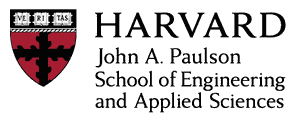

# CS1090A Introduction to Data Science

### Section 11 — Random Forests: Imbalanced Classes, Tuning and Interpretation

In [ ]:
# Provided — setup. On Colab this fetches the data files this notebook needs.
# Everywhere else it does nothing except confirm they are already here.
#
# Generated at publish time; see utils/inject_colab_bootstrap.py. Editing this cell
# in the public repo is wasted work -- the next publish overwrites it.
import os
import shutil
import subprocess
import sys

_REPO    = "https://github.com/Harvard-CS1090/2026-CS1090A-public"
_REF     = "sec11-2026"
_SECTION = "sec11"

_DIRNAME = _REPO.rstrip("/").split("/")[-1].removesuffix(".git")

if os.path.isdir("data"):
    print(f"data/ is present -- nothing to fetch.")
elif "google.colab" not in sys.modules:
    raise RuntimeError(
        "This notebook reads its inputs from a data/ folder, which is not here.\n"
        "It does not fetch them from the live web -- that is deliberate, and Part 1\n"
        "explains why.\n\n"
        "Fix: get the whole folder, not just the notebook --\n"
        f"    git clone --branch {_REF} {_REPO}\n"
        f"    cd {_DIRNAME}/{_SECTION}\n"
        "    jupyter lab\n\n"
        "Then open this notebook from in there. (On Colab, this cell fetches it for you.)"
    )
else:
    print("Colab detected, no data/ -- fetching it once...")
    _tmp = "/content/_cs1090a_materials"
    if not os.path.isdir(_tmp):
        _r = subprocess.run(
            ["git", "clone", "--depth", "1", "--branch", _REF, _REPO, _tmp],
            capture_output=True, text=True,
        )
        if _r.returncode != 0:
            raise RuntimeError(
                f"Could not download the data files from {_REPO} (ref {_REF}).\n\n"
                f"git said: {_r.stderr.strip().splitlines()[-1] if _r.stderr.strip() else 'no output'}\n\n"
                "This is not something you did wrong. Post on Ed with this message and\n"
                "a TF will sort it out; meanwhile the section notebook will not run here."
            )
    _dir = os.path.join(_tmp, _SECTION)
    _src = os.path.join(_dir, "data")
    if not os.path.isdir(_src):
        raise RuntimeError(
            f"Cloned {_REPO} at {_REF} but found no {_SECTION}/data in it.\n"
            "The published bundle is incomplete -- please report this on Ed."
        )
    shutil.copytree(_src, "data")

    # Sibling modules too, not just data/. Section 1 does `from section_helpers import
    # Recorded`; fetching data/ alone leaves that import failing three cells later,
    # which reads as "the notebook is broken" rather than "setup was incomplete".
    _mods = [f for f in os.listdir(_dir) if f.endswith(".py")]
    for _m in _mods:
        shutil.copy(os.path.join(_dir, _m), _m)

    print(f"data/ ready ({len(os.listdir('data'))} entries)"
          + (f", plus {', '.join(sorted(_mods))}." if _mods else "."))


<div style="background:#E8F1FF; border-left:6px solid #2563EB; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🎯 Objectives — what you should be able to do by the end</div>
<div>
<ul>
<li>Explain why accuracy is misleading when one class is rare, and report recall, precision and F1 for the rare class instead.</li>
<li>Correct for an imbalance in four ways (class weights, undersampling, oversampling, SMOTE), say what each one changes about the trees' training rows, and compare them fairly.</li>
<li>Explain why resampling must happen inside each training fold, never before the data are split.</li>
<li>Tune a random forest's <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_features</code> with out-of-bag predictions, explain why <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_features</code> = p is bagging, and decide whether a difference between two settings is larger than the noise.</li>
<li>Rank the predictors with MDI and with out-of-fold permutation importance, and explain where and why the two disagree.</li>
<li>Explain one prediction with LIME, written by hand, and check how well the explanation fits the forest.</li>
</ul>
</div>
</div>

**Colored boxes:** 🤔 commit to a prediction before running the code · 🏋️ write code (look for `# your code here`) · 💬 stop running cells and discuss · ⭐ the point of the exercise · 🧠 what to carry out of the room · 🔍 an appendix item to work through on your own afterward.

This section is a small project with one question: **can a random forest find the good wines?**
A wine merchant receives the laboratory measurements of a wine (its acidity, sugar, alcohol and so
on) before anyone tastes it, and wants to know which wines are worth sending to a tasting panel.
Only about one wine in five is rated good, so this is a classification problem with an
**imbalanced** outcome: one class is much rarer than the other.

Every model in this section is a **random forest**: $B$ decision trees, each grown on a bootstrap
sample of the training rows, with each split chosen among a random subset of the predictors, and a
prediction made by averaging the trees' predicted probabilities.

The project has four parts:

1. **Part 1** fits a default forest and shows what accuracy hides when one class is rare.
2. **Part 2** tries four corrections for the imbalance (class weights, undersampling, oversampling and SMOTE) and compares them fairly.
3. **Part 3** tunes the forest's `max_features` with out-of-bag predictions, and asks whether the differences are real.
4. **Part 4** asks what the forest learned: which measurements matter overall (MDI and permutation importance), and why it made one particular prediction (LIME).

The appendix has the same tools applied to a single decision tree, a grid search over two forest settings at once, and bagging itself.

## Setup

In [ ]:
# On Colab only: install the versions this section needs (Colab does not include lime, and its scikit-learn may be older than 1.9)
import shutil
import subprocess
import sys

if "google.colab" in sys.modules:
    packages = ["scikit-learn>=1.9,<2", "imbalanced-learn>=0.14,<0.15", "lime>=0.2,<0.3"]
    installer = ["uv", "pip", "install", "--system"] if shutil.which("uv") else [sys.executable, "-m", "pip", "install"]
    subprocess.run(installer + ["--quiet"] + packages, check=True)
    print("installed:", ", ".join(packages))

In [ ]:
# Libraries used in this section
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import make_pipeline
from imblearn.under_sampling import RandomUnderSampler
from lime.lime_tabular import LimeTabularExplainer
from sklearn.base import clone
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", context="notebook")

### The wine data

Each row is one Portuguese "vinho verde" wine (Cortez, Cerdeira, Almeida, Matos and Reis, 2009): 500
red and 500 white wines, with eleven laboratory measurements and a quality score. The score is the
median grade given by at least three tasters, on a scale from 0 to 10. We call a wine **good** when
its score is 7 or more.

| Column | What it measures |
|---|---|
| `fixed acidity`, `volatile acidity`, `citric acid` | acids, in g/L; volatile acidity is acetic acid, which tastes of vinegar |
| `residual sugar` | sugar left after fermentation, g/L |
| `chlorides` | salt, g/L |
| `free sulfur dioxide`, `total sulfur dioxide` | a preservative, mg/L |
| `density` | g/cm³; it falls as alcohol rises and rises with sugar |
| `pH`, `sulphates` | acidity on the pH scale; a wine additive, g/L |
| `alcohol` | % of the volume |
| `red` | 1 for a red wine, 0 for a white |
| `quality` | the tasters' median score; **the outcome is `good` = quality of 7 or more** |

In [ ]:
# Load the wines, remove exact duplicate rows, and define the outcome
wines = pd.read_csv("data/wines.csv").drop(columns="Unnamed: 0")
print(f"{len(wines)} rows, {wines.duplicated().sum()} of them exact copies of an earlier row")
wines = wines.drop_duplicates().reset_index(drop=True)
wines["good"] = (wines["quality"] >= 7).astype(int)
X = wines.drop(columns=["quality", "good"])
y = wines["good"]
print(f"{len(wines)} distinct wines, {X.shape[1]} predictors; share rated good: {y.mean():.3f}")

We remove the duplicate rows because a copy of a wine could land in the training rows and its twin
in the validation rows, and the model would then be tested on a wine it has already seen. Part 2
shows how much copies on both sides of a split can inflate a score.

We hold out 25% of the wines as a test set, stratified so both sets have the same share of good
wines. Its labels are used once, to score the final forest at the end of Part 3. Every comparison
and every choice uses five-fold cross-validation or out-of-bag predictions on the development
wines, with the same folds every time. After the test score, the forest is fixed; Part 4 looks at
one test wine only to explain a mistake, and nothing in Part 4 changes the model.

In [ ]:
# Hold out 25% as a test set; five stratified folds on the development wines, reused below
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.25, random_state=109, stratify=y)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
print(f"development: {len(y_dev)} wines, {y_dev.sum()} good   test: {len(y_test)} wines, {y_test.sum()} good")

In [ ]:
# A random forest with 200 trees; every forest in the section is built with this function
def forest(random_state=0, **settings):
    return RandomForestClassifier(n_estimators=200, random_state=random_state, n_jobs=-1, **settings)


# Accuracy, and recall, precision and F1 for each class, from one set of predictions
def report(y_true, y_pred):
    return pd.Series({
        "accuracy": (y_true == y_pred).mean(),
        "recall, good": recall_score(y_true, y_pred),
        "precision, good": precision_score(y_true, y_pred, zero_division=0),
        "F1, good": f1_score(y_true, y_pred),
        "recall, not good": recall_score(y_true, y_pred, pos_label=0),
        "macro-F1": f1_score(y_true, y_pred, average="macro"),
    })


# The confusion matrix with labeled rows (true class) and columns (predicted class)
def confusion_table(y_true, y_pred):
    names = ["not good", "good"]
    return pd.DataFrame(confusion_matrix(y_true, y_pred), index=[f"true {n}" for n in names],
                        columns=[f"predicted {n}" for n in names])

## Part 1. Accuracy and recall for a rare class

### Recall, precision and F1 for the rare class

From the confusion matrix (true class in rows, predicted class in columns), with "good" as the class
we care about:

- **Recall** for good wines: of the wines that truly are good, the share the model predicts as good. This is what the merchant cares about most: a good wine with low recall is never tasted.
- **Precision** for good wines: of the wines the model predicts as good, the share that truly are. Low precision wastes the tasting panel's time.
- **F1** for good wines: $2 \cdot \text{precision} \cdot \text{recall} / (\text{precision} + \text{recall})$, which is high only when both are high.
- **Macro-F1**: the average of the F1 for good wines and the F1 for not-good wines, so each class counts equally however many wines it has.

Every number below is computed from **out-of-fold** predictions: each development wine is predicted
by the forest trained on the four folds that did not contain it (`cross_val_predict`).

### The default forest against always predicting not good

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict</div>
<div>
About 19% of the wines are good. A "model" that predicts <em>not good</em> for every wine: what is its
accuracy, and what is its recall for good wines? Then guess: will a default random forest have a
much higher accuracy than that?
</div>
</div>

In [ ]:
# The default forest, out of fold, beside the predictor that always says "not good"
default_pred = cross_val_predict(forest(), X_dev, y_dev, cv=skf)
always_not_good = np.zeros(len(y_dev), dtype=int)
pd.DataFrame({"always not good": report(y_dev, always_not_good),
              "default forest": report(y_dev, default_pred)}).round(3)

In [ ]:
# Where the default forest's errors are
confusion_table(y_dev, default_pred)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 1: what the default forest does</div>
<div>
<ol>
<li>The default forest's accuracy is a few points above "always not good". Which recall shows that it is still missing most good wines, and how many of the good development wines does it miss?</li>
<li>Why would a forest trained to get as many wines right as possible end up ignoring most of the rare class?</li>
</ol>
</div>
</div>

## Part 2. Four ways to correct for the imbalance

All four corrections make the good wines count for more when the trees are grown. They differ in
how:

| Correction | What it changes | Training rows afterward |
|---|---|---|
| **Class weights**, `class_weight="balanced"` | in a forest, each tree's bootstrap sample draws good wines more often and not-good wines less often | the same rows, drawn in different proportions |
| **Random undersampling** | removes randomly chosen not-good wines until the two classes are equal | fewer rows: information is thrown away |
| **Random oversampling** | adds exact copies of randomly chosen good wines until the classes are equal | more rows, but no new information |
| **SMOTE** | adds new, synthetic good wines between existing good wines and their nearest good neighbors | more rows, with new but invented values |

### Class weights

With $N$ wines, $K = 2$ classes and $N_k$ wines in class $k$, `"balanced"` gives every wine of
class $k$ the weight $W_k = N / (K \cdot N_k)$. On the development wines that is
$726 / (2 \cdot 138) \approx 2.63$ for a good wine and $726 / (2 \cdot 588) \approx 0.62$ for a
not-good wine, so the two classes have the same total weight.

How the weights are used depends on the model. In a single `DecisionTreeClassifier`, a wine's
weight multiplies its count in the impurity and in its leaf's vote. In a random forest
(scikit-learn 1.9 and later), the weights instead set each wine's chance of being drawn into a
tree's bootstrap sample. The next cell counts the draws in each tree.

In [ ]:
# Draws per tree from each class, in a forest without and with class weights
good = (y_dev == 1).to_numpy()
draws = {}
for name, model in {"no weights": forest(), 'class_weight="balanced"': forest(class_weight="balanced")}.items():
    counts = np.array([np.bincount(s, minlength=len(y_dev)) for s in model.fit(X_dev, y_dev).estimators_samples_])
    draws[name] = {"draws of good wines": counts[:, good].sum(axis=1).mean(),
                   "draws of not-good wines": counts[:, ~good].sum(axis=1).mean(),
                   "distinct not-good wines in the sample": (counts[:, ~good] > 0).sum(axis=1).mean()}
pd.DataFrame(draws).round(1)

Each tree still draws 726 wines, but with class weights about half of the draws are good wines,
so each good wine appears several times in a tree's sample and many not-good wines do not appear
at all. A class-weighted forest is therefore a form of resampling done inside the forest.

### How SMOTE makes a synthetic wine

**SMOTE** (Synthetic Minority Oversampling Technique) makes one synthetic good wine like this:

1. pick a good wine $x_i$ (the **anchor**);
2. find its nearest good wines, and pick one of them, $x_{nn}$ (the **neighbor**);
3. draw a random number $u$ between 0 and 1, and set $x_{\text{new}} = x_i + u\,(x_{nn} - x_i)$.

The new wine lies on the straight line between the two good wines: with $u = 0$ it is the anchor,
with $u = 1$ the neighbor, and with $u = 0.5$ halfway between them, in every column at once.
`SMOTE` in the `imbalanced-learn` package repeats this until the classes are equal, choosing the
neighbor at random among the anchor's 5 nearest good wines.

The distance in step 2 should be computed on standardized columns. On the raw columns, total sulfur
dioxide (in mg/L) has by far the largest spread, so it would decide which wine is nearest almost on
its own. `SMOTE` does not standardize, so below a `StandardScaler` comes before it in the pipeline.
SMOTE also treats the 0/1 column `red` as a number; for 0/1 and category columns, `imbalanced-learn`
has `SMOTENC`.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 1: one synthetic wine by hand (3 min)</div>
<div>
The cell finds an anchor, its nearest good neighbor (on standardized columns) and a random <code style="background:rgba(0,0,0,0.06); color:#1F2937;">u</code>. Complete
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">synthetic</code> with the formula above. Both <code style="background:rgba(0,0,0,0.06); color:#1F2937;">anchor</code> and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">neighbor</code> are pandas
Series, so the arithmetic works column by column. The table that follows should show every value of
the synthetic wine between the anchor's and the neighbor's.
</div>
</div>

In [ ]:
# One synthetic good wine on the line between a good wine and its nearest good neighbor
good_dev = X_dev[y_dev == 1]
good_std = (good_dev - X_dev.mean()) / X_dev.std()       # standardized, so every column counts equally in the distance
anchor = good_dev.iloc[1]
neighbors = NearestNeighbors(n_neighbors=2).fit(good_std)    # 2: the wine itself, then its nearest good wine
_, positions = neighbors.kneighbors(good_std.iloc[[1]])
neighbor = good_dev.iloc[positions[0][1]]
u = np.random.default_rng(0).random()

# your code here
synthetic = ...                # anchor plus u times the step from the anchor to the neighbor
print(f"u = {u:.3f}")
pd.DataFrame({"anchor": anchor, "neighbor": neighbor, "synthetic": synthetic}).T.round(3)

### Resampling inside the training folds

A resampled dataset contains wines that are copies (oversampling) or near-copies (SMOTE) of each
other. If we resample **before** splitting into folds, a copy can land in a training fold while its
original lands in the validation fold, and the forest is then tested on wines it has, in effect,
already seen. The cell below does exactly that wrong thing and compares it with the right way, in
which each training fold is resampled on its own and the validation fold is left untouched.

`imbalanced-learn`'s `make_pipeline` does the right thing automatically: inside
`cross_val_predict`, the resampling step is applied when the pipeline is fitted on the four training
folds, and skipped when it predicts the fifth.

In [ ]:
# Wrong: oversample all development wines, then cross-validate. Right: oversample inside each training fold.
X_over, y_over = RandomOverSampler(random_state=0).fit_resample(X_dev, y_dev)
wrong_pred = cross_val_predict(forest(), X_over, y_over, cv=skf)
right_pred = cross_val_predict(make_pipeline(RandomOverSampler(random_state=0), forest()), X_dev, y_dev, cv=skf)
pd.DataFrame({"oversampled before splitting (wrong)": report(y_over, wrong_pred),
              "oversampled inside each training fold": report(y_dev, right_pred)}).round(3)

The first column reports a much higher F1 for good wines than the second. Nothing about the model
changed between the two columns, only where the copies were allowed to go: in the first column,
copies of each validation wine were among the training rows.

### Comparing the four corrections

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 2: the corrections as pipelines (4 min)</div>
<div>
Complete the dictionary <code style="background:rgba(0,0,0,0.06); color:#1F2937;">corrections</code> with the two missing entries, written like the
oversampling entry: <code style="background:rgba(0,0,0,0.06); color:#1F2937;">"random undersampling"</code> with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">RandomUnderSampler(random_state=0)</code>,
and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">"SMOTE"</code> with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">StandardScaler()</code> then <code style="background:rgba(0,0,0,0.06); color:#1F2937;">SMOTE(random_state=0)</code>, each followed by <code style="background:rgba(0,0,0,0.06); color:#1F2937;">forest()</code> in a
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">make_pipeline</code>. The scaler only changes which neighbors SMOTE finds; a tree's splits do not depend
on the scale of a column. The cell then computes the out-of-fold report of every entry.
</div>
</div>

In [ ]:
# Every correction, with the same forest and the same folds; out-of-fold report for each
corrections = {
    "no correction": forest(),
    "class weights": forest(class_weight="balanced"),
    "random oversampling": make_pipeline(RandomOverSampler(random_state=0), forest()),
    # your code here
    "random undersampling": ...,
    "SMOTE": ...,
}
assert {"random undersampling", "SMOTE"} <= set(corrections), "add the two missing entries to corrections"
correction_table = pd.DataFrame({name: report(y_dev, cross_val_predict(model, X_dev, y_dev, cv=skf))
                                 for name, model in corrections.items()})
correction_table.round(3)

### Oversampling and the size of each tree's sample

Random oversampling and class weights both give good wines about half of each tree's draws, yet
oversampling changed less. An oversampled training set has more rows than the original, and each
tree's bootstrap sample has as many draws as there are rows, so every tree still contains most of
the not-good wines. `max_samples` sets the number of draws as a share of the rows. The cell sets it
to (original rows) / (oversampled rows), so that each oversampled tree draws as many wines as a
class-weighted tree.

In [ ]:
# Random oversampling with full-size bootstrap samples, and with samples the size of the original training rows
share = len(y_dev) / (2 * (y_dev == 0).sum())     # original rows / oversampled rows
pd.DataFrame({name: report(y_dev, cross_val_predict(make_pipeline(RandomOverSampler(random_state=0), forest(**settings)),
                                                    X_dev, y_dev, cv=skf))
              for name, settings in {"oversampling": {}, f"oversampling, max_samples={share:.2f}": {"max_samples": share}}.items()
              }).round(3)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 2: choosing a correction</div>
<div>
<ol>
<li>Compared with no correction, which recall rises and which falls for every correction? Explain the trade-off in terms of the merchant's tasting panel.</li>
<li>Undersampling finds the most good wines. Why is it still not the obvious choice? Look at its precision, and at how many development wines it trains on.</li>
<li>Oversampling and class weights both give good wines about half of each tree's draws. Using the draw counts and the last table, why did oversampling change less?</li>
<li>Which correction would you carry into the rest of the project, and why?</li>
</ol>
</div>
</div>

<div style="background:#F3E8FF; border-left:6px solid #7E22CE; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">⭐ Insight</div>
<div>
In this project no correction made the forest more accurate. Each one moved the trade-off between the
two recalls toward the rare class. Compare corrections with the numbers that match the decision
(recall and precision for the rare class, macro-F1), always from predictions on wines the forest did
not train on, and resample only inside the training folds.
</div>
</div>

## Part 3. Tuning the forest: `max_features` from 1 to p

At every split, a random forest chooses the best split among `max_features` predictors drawn at
random, not among all $p$ of them. Here $p = 12$. (The lecture writes $J$ for the number of
predictors and $J'$ for the number drawn at each split.)

- With `max_features` = $p$, every split may use any predictor, so the trees differ only because they are grown on different bootstrap samples. That is **bagging**.
- With a small `max_features`, a tree often cannot use the strongest predictor at a split, so the trees differ more from each other. Averaging trees that make *different* errors cancels more of those errors than averaging trees that make the same ones. The price is that each single tree can be a little worse.
- scikit-learn's default for classification is `max_features="sqrt"`: $\sqrt{12} \approx 3.46$, rounded down to 3.

We keep the class weights from Part 2 and fix `min_samples_leaf=3`, a middle value, so that only
`max_features` changes. Appendix A5 tunes both settings together.

### Out-of-bag predictions

Each tree is grown on a bootstrap sample of $N$ draws. Without weights, a given wine is left out of a
tree's sample with probability $(1 - 1/N)^N \approx e^{-1} \approx 0.37$. For each wine, the trees that
left it out form a smaller forest, and their averaged prediction is the wine's **out-of-bag (OOB)**
prediction. With `oob_score=True`, scikit-learn stores the OOB class probabilities in
`oob_decision_function_`. OOB predictions need no folds and cost a single fit, so we use them to tune.

With class weights, a good wine is drawn about 2.63 times per tree on average, so it is left out with
probability about $e^{-2.63} \approx 0.07$: its OOB prediction comes from roughly 14 of the 200 trees.
A not-good wine is left out with probability about $e^{-0.62} \approx 0.54$. The OOB predictions for good
wines are therefore noisier than those for not-good wines.

OOB predictions would not be valid after resampling in a pipeline: the forest would treat a copy as a
different wine, so a tree that left a wine out could still have trained on its copy.

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 3: tune max_features with OOB macro-F1 (4 min)</div>
<div>
For each value <code style="background:rgba(0,0,0,0.06); color:#1F2937;">m</code> in the list, fit <code style="background:rgba(0,0,0,0.06); color:#1F2937;">forest(max_features=m, min_samples_leaf=3,
class_weight="balanced", oob_score=True)</code> on the development wines, turn its
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">oob_decision_function_</code> into class predictions with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">.argmax(axis=1)</code>, and compute
the macro-F1 of those predictions against <code style="background:rgba(0,0,0,0.06); color:#1F2937;">y_dev</code>.
</div>
</div>

In [ ]:
# OOB macro-F1 for each value of max_features, from 1 to p = 12
oob_rows = []
for m in [1, 2, 3, 4, 6, 8, 12]:
    # your code here
    model = ...                     # fit the forest with this max_features
    oob_pred = ...                  # the class with the larger OOB probability, for each wine
    oob_macro_f1 = ...              # macro-F1 of the OOB predictions
    oob_rows.append({"max_features": m, "OOB macro-F1": oob_macro_f1})
oob_table = pd.DataFrame(oob_rows).set_index("max_features")
oob_table.round(3)

Before reading the winner off this table, two more pieces of evidence: how different the trees are
for different values of `max_features`, and how much the score moves when we estimate it a second
way or change only the forest's random seed.

### How alike the trees are for different values of `max_features`

In [ ]:
# For three values of max_features: the predictor at the root of each tree, and how alike the trees' predictions are
tree_rows = []
for m in [1, 3, 12]:
    model = forest(max_features=m, min_samples_leaf=3, class_weight="balanced").fit(X_dev, y_dev)
    roots = pd.Series([X.columns[t.tree_.feature[0]] for t in model.estimators_]).value_counts()
    tree_probs = np.array([t.predict_proba(X_dev.to_numpy())[:, 1] for t in model.estimators_])
    correlations = np.corrcoef(tree_probs)[np.triu_indices(len(tree_probs), k=1)]
    tree_rows.append({"max_features": m, "most common root": f"{roots.index[0]} ({roots.iloc[0]} of 200 trees)",
                      "mean correlation between two trees": correlations.mean()})
pd.DataFrame(tree_rows).set_index("max_features").round(3)

### Cross-validation and a second seed

In [ ]:
# The same settings scored two more ways: five-fold cross-validated macro-F1, and OOB macro-F1 of a forest with seed 1
cv_rows = []
for m in oob_table.index:
    scores = cross_val_score(forest(max_features=m, min_samples_leaf=3, class_weight="balanced"),
                             X_dev, y_dev, cv=skf, scoring="f1_macro")
    seed1 = forest(random_state=1, max_features=m, min_samples_leaf=3, class_weight="balanced", oob_score=True).fit(X_dev, y_dev)
    cv_rows.append({"max_features": m, "OOB macro-F1, seed 1": f1_score(y_dev, seed1.oob_decision_function_.argmax(axis=1), average="macro"),
                    "CV macro-F1": scores.mean(), "SD over folds": scores.std(ddof=1)})
tuning = oob_table.rename(columns={"OOB macro-F1": "OOB macro-F1, seed 0"}).join(pd.DataFrame(cv_rows).set_index("max_features"))
tuning.round(3)

In [ ]:
# The three estimates on one plot
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tuning.index, tuning["OOB macro-F1, seed 0"], marker="o", color="#7E22CE", label="OOB, seed 0")
ax.plot(tuning.index, tuning["OOB macro-F1, seed 1"], marker="s", linestyle="--", color="#A78BFA", label="OOB, seed 1")
ax.errorbar(tuning.index, tuning["CV macro-F1"], yerr=tuning["SD over folds"], marker="o", color="#DC2626",
            capsize=3, label="cross-validated (± 1 SD over folds)")
ax.set(xlabel="max_features (12 = bagging)", ylabel="macro-F1", title="tuning max_features")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.show()

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 3: is there a best max_features?</div>
<div>
<ol>
<li>With <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_features=12</code>, which predictor sits at the root of almost every tree, and why? What happens to the trees' correlation as <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_features</code> falls?</li>
<li>Do OOB and cross-validation agree on the best value? Do the two OOB seeds agree? Compare the differences between settings with the SD over folds.</li>
<li>Which value would you choose, and why?</li>
</ol>
</div>
</div>

### Scoring the final forest on the test set

We fix the final forest: class weights, `max_features="sqrt"`, `min_samples_leaf=3`. The cell fits it
and the default forest from Part 1 on all development wines and evaluates both, once, on the test wines.

In [ ]:
# The final forest and the default forest, fitted on all development wines, evaluated once on the test set
final = forest(max_features="sqrt", min_samples_leaf=3, class_weight="balanced").fit(X_dev, y_dev)
default = forest().fit(X_dev, y_dev)
pd.DataFrame({"default forest": report(y_test, default.predict(X_test)),
              "final forest": report(y_test, final.predict(X_test))}).round(3)

The final forest finds far more of the good test wines than the default forest, at the cost of
precision, as in Part 2. The test set has fewer than 50 good wines, so each of these recalls moves by
about 0.02 for every wine, and the exact values should not be read to the third decimal.

## Part 4. What did the forest learn?

A forest of 200 trees cannot be read like a single small tree. We ask two different questions
instead:

- **Globally:** which measurements matter for the forest's predictions overall? (MDI and permutation importance)
- **Locally:** why did the forest give *this* wine the probability it did? (LIME)

### MDI and permutation importance

To check what each method says about predictors we *know* are useless, we add four columns of random
numbers to the development wines. They are unrelated to the outcome and differ only in how many
distinct values they take: `noise_2` takes 2 values (0 or 1), `noise_5` takes 5, `noise_20` takes 20,
and `noise_continuous` is drawn from a normal distribution, so every wine has a different value.

- **MDI** (mean decrease in impurity, scikit-learn's `feature_importances_`): every split lowers the Gini impurity of the training wines that reach it. For each tree, MDI adds up those decreases for each predictor, weighted by the share of the tree's training wines at the node, and rescales them to sum to 1; the forest's MDI is the average over its trees. It is computed from the training wines only.
- **Permutation importance**: shuffle one column of wines the forest did *not* train on, which breaks the column's link with the outcome while keeping its values, and measure how much the forest's macro-F1 drops. A predictor the forest does not rely on gives a drop near 0. We compute it **out of fold**: for each of the five folds, a copy of the forest (`clone`) is fitted on the other four folds, and each column of the held-out fold is shuffled 10 times. The **SD across folds** shows how much the importance depends on which wines were held out.

In [ ]:
# Add four columns of pure noise with 2, 5, 20 and all-different values; fit the final forest's settings on all development wines, for MDI
rng = np.random.default_rng(0)
noise_columns = ["noise_2", "noise_5", "noise_20", "noise_continuous"]
X_dev_noise = X_dev.assign(noise_2=rng.integers(0, 2, len(X_dev)), noise_5=rng.integers(0, 5, len(X_dev)),
                           noise_20=rng.integers(0, 20, len(X_dev)), noise_continuous=rng.normal(size=len(X_dev)))
noisy = forest(max_features="sqrt", min_samples_leaf=3, class_weight="balanced").fit(X_dev_noise, y_dev)

<div style="background:#FFF7CC; border-left:6px solid #D97706; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🤔 Predict</div>
<div>
None of the four noise columns carries information about the outcome. Will they get the same MDI?
If not, which will get the most? What will their permutation importance be?
</div>
</div>

In [ ]:
# Permutation importance out of fold: fit a copy on four folds, shuffle each column of the fifth 10 times
fold_drops = []
for train, held_out in skf.split(X_dev_noise, y_dev):
    fold_model = clone(noisy).fit(X_dev_noise.iloc[train], y_dev.iloc[train])
    result = permutation_importance(fold_model, X_dev_noise.iloc[held_out], y_dev.iloc[held_out],
                                    scoring="f1_macro", n_repeats=10, random_state=0, n_jobs=-1)
    fold_drops.append(result.importances_mean)
fold_drops = pd.DataFrame(fold_drops, columns=X_dev_noise.columns)
fold_drops.round(3)

In [ ]:
# MDI beside the permutation importance's mean and SD across the five folds
importance = pd.DataFrame({"MDI": noisy.feature_importances_, "permutation": fold_drops.mean(),
                           "SD across folds": fold_drops.std(ddof=1)}, index=X_dev_noise.columns)
importance["MDI rank"] = importance["MDI"].rank(ascending=False).astype(int)
importance["permutation rank"] = importance["permutation"].rank(ascending=False).astype(int)
importance.sort_values("MDI", ascending=False).round(4)

In [ ]:
# The two importances side by side, with the four noise columns in red
order = importance.sort_values("MDI").index
colors = ["#DC2626" if name in noise_columns else "#4B5563" for name in order]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
axes[0].barh(order, importance.loc[order, "MDI"], color=colors)
axes[0].set(xlabel="MDI (share of the impurity decrease)", title="MDI, from the training wines")
axes[1].barh(order, importance.loc[order, "permutation"], xerr=importance.loc[order, "SD across folds"], color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="drop in macro-F1 when the column is shuffled (± 1 SD across folds)", title="permutation importance, out of fold")
plt.tight_layout()
plt.show()

In [ ]:
# Correlations between alcohol, density and residual sugar on the development wines, for Checkpoint 4
X_dev[["alcohol", "density", "residual sugar"]].corr().round(2)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 4: reading the two importances</div>
<div>
<ol>
<li>Both methods put alcohol first. Order the four noise columns by MDI. How does the MDI of <code style="background:rgba(0,0,0,0.06); color:#1F2937;">noise_continuous</code> compare with the real measurements, and how do the noise columns' permutation importances compare with their SD across folds? Why does a random column with more distinct values get more MDI?</li>
<li><code style="background:rgba(0,0,0,0.06); color:#1F2937;">red</code> is a real measurement with two values. Which noise column is its MDI close to, and what does that say about reading MDI for a 0/1 column?</li>
<li>Most permutation importances are smaller than their SD across folds, and some folds give a negative drop. What does a negative drop mean, and what can you conclude from a mean smaller than its SD?</li>
<li>Density ranks high by MDI and low by permutation importance, and it is correlated with alcohol. How could that correlation affect each method?</li>
</ol>
</div>
</div>

### LIME: explaining one prediction

Importance scores describe the forest on average. To explain **one** prediction, LIME (Local
Interpretable Model-agnostic Explanations) fits a simple model that imitates the forest near that wine:

1. **Perturb:** create many fake wines around the wine we want to explain, by adding random noise to each of its measurements.
2. **Ask the forest:** compute the forest's probability of "good" for every fake wine.
3. **Weight:** give each fake wine a weight that is large when it is close to the original wine and small when it is far away.
4. **Fit:** fit a weighted linear regression of the forest's probabilities on the fake wines' measurements. Its coefficients are the explanation: how the forest's probability changes, over the fake wines, when one measurement increases.

We work with **standardized** measurements (in standard deviations of the development wines), so the
noise in step 1 has the same size in every column and the coefficients are comparable: each one is the
change in the probability of "good" per one-SD increase. `red` stays at the wine's own value, because a
wine is red or white, not in between. The weight in step 3 is $\exp(-d^2 / (2w^2))$, where $d$ is the
distance from the original wine and $w = 0.75\sqrt{p}$; both are the `lime` package's defaults. With
one SD of noise in every column at once, the fake wines are not close copies of the wine. How far they
spread is a choice, and the coefficients change with it.

The forest is now fixed. To understand one of its mistakes, we explain the good test wine to which it
gives the **lowest** probability of being good: a wine the merchant would never send to the panel.
Looking at this wine changes nothing about the model.

In [ ]:
# The good test wine with the lowest predicted probability of being good
test_prob = pd.Series(final.predict_proba(X_test)[:, 1], index=X_test.index)
missed = test_prob[y_test == 1].idxmin()
print(f"wine {missed}: rated {wines.loc[missed, 'quality']}, forest's probability of good {test_prob[missed]:.3f}")
X_test.loc[[missed]]

<div style="background:#E9F8EE; border-left:6px solid #16A34A; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🏋️ Exercise 4: LIME by hand (4 min)</div>
<div>
Steps 1 to 3 are provided. Complete step 4: fit <code style="background:rgba(0,0,0,0.06); color:#1F2937;">Ridge(alpha=1.0)</code> (a linear regression with a
small penalty; it is the model the <code style="background:rgba(0,0,0,0.06); color:#1F2937;">lime</code> package fits) with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">fake_std - wine_std</code> as the predictors (the
fake wines' standardized distances from the original wine in each column), <code style="background:rgba(0,0,0,0.06); color:#1F2937;">fake_prob</code> as the
outcome, and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">sample_weight=weights</code>. The cell then lists the coefficients from the largest in
absolute value.
</div>
</div>

In [ ]:
# LIME by hand: perturb, ask the forest, weight by closeness, fit a weighted linear model
mean, sd = X_dev.mean(), X_dev.std()
wine_std = ((X_test.loc[missed] - mean) / sd).to_numpy()

# 1. perturb: 5,000 fake wines, each standardized measurement moved by a standard normal amount; red stays as it is
noise = np.random.default_rng(0).normal(size=(5000, X.shape[1]))
noise[:, X.columns.get_loc("red")] = 0
fake_std = wine_std + noise
fake_wines = pd.DataFrame(fake_std * sd.to_numpy() + mean.to_numpy(), columns=X.columns)   # back to raw units
# 2. ask the forest
fake_prob = final.predict_proba(fake_wines)[:, 1]
# 3. weight: close fake wines count more
distance = np.sqrt(((fake_std - wine_std) ** 2).sum(axis=1))
width = 0.75 * np.sqrt(X.shape[1])
weights = np.exp(-distance ** 2 / (2 * width ** 2))
# 4. fit
# your code here
local_model = Ridge(alpha=1.0).fit(...)      # predictors, outcome, sample_weight

lime_by_hand = pd.Series(local_model.coef_, index=X.columns, name="change in P(good) per +1 SD")
lime_by_hand.drop("red").sort_values(key=abs, ascending=False).round(3)

### Checking the linear model's fit to the forest

The linear model is an approximation of the forest, so check it before reading its coefficients:
compare its prediction at the wine itself (its intercept, because the predictors are distances from
the wine) with the forest's probability, and look at its weighted $R^2$ on the fake wines.

In [ ]:
# The local model at the wine against the forest, and its weighted R² on the fake wines
print(f"forest's probability at the wine:  {test_prob[missed]:.3f}")
print(f"local model's value at the wine:   {local_model.intercept_:.3f}")
print(f"weighted R² on the fake wines:     {local_model.score(fake_std - wine_std, fake_prob, sample_weight=weights):.3f}")

In [ ]:
# How the missed wine compares with the typical good and not-good development wine
pd.DataFrame({"missed wine": X_test.loc[missed],
              "average good wine": X_dev[y_dev == 1].mean(),
              "average not-good wine": X_dev[y_dev == 0].mean()}).T.round(3)

<div style="background:#FDECEC; border-left:6px solid #DC2626; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">💬 Discuss — Checkpoint 5: why was this good wine missed?</div>
<div>
<ol>
<li>Which measurements is the forest's probability most sensitive to over the fake wines, and in which direction? Use the comparison table to say which of them make this wine look like a not-good wine.</li>
<li>What does the alcohol coefficient say, exactly? Does it say that adding alcohol to this wine would make it better?</li>
<li>Compare the local model's value at the wine with the forest's probability, and look at its R². How far should you trust the coefficients?</li>
</ol>
</div>
</div>

<div style="background:#F3F4F6; border-left:6px solid #4B5563; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🧠 Takeaways — four things to remember</div>
<div>
<ol>
<li><strong>When one class is rare, a forest that maximizes accuracy ignores most of it.</strong> Report recall and precision for the rare class and macro-F1, computed from predictions on rows the forest did not train on.</li>
<li><strong>Class weights, undersampling, oversampling and SMOTE all make the rare class count for more, and resampling must happen only inside each training fold.</strong> Resampling before splitting puts copies of a row on both sides of the split and inflates the score. In a random forest, class weights change how often each class is drawn into the trees' bootstrap samples. In this project no correction raised accuracy; each moved the trade-off between the two recalls.</li>
<li><strong><code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_features</code> controls how different the trees are, and <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_features</code> = p is bagging.</strong> Tune it with OOB or cross-validated scores, and compare the differences between settings with the SD over folds before choosing a winner.</li>
<li><strong>MDI is computed from the training rows and favors columns with many distinct values; permutation importance, computed out of fold, measures how much the held-out score depends on each column.</strong> LIME explains one prediction with a weighted linear model fitted to the forest's outputs around that row. Check how well it fits before reading its coefficients, and read them as statements about the model's predictions, not about what would happen to a real wine.</li>
</ol>
<p><strong>Final check:</strong> a classmate oversamples the whole development set, runs five-fold cross-validation and reports a very high F1 for good wines. What do you tell them, and what should they do instead?</p>
</div>
</div>

---

## Appendix: things to try later

**Nothing below is expected during section.** Each item is a 🔍 Explore box: the code below it is
provided and runs as-is, and the work is reading the output and answering the questions.

- **A1**: moving the decision threshold instead of reweighting or resampling.
- **A2**: how many trees a forest needs.
- **A3**: the same LIME explanation from the `lime` package.
- **A4**: class weights for a single decision tree, searched together with its depth by `GridSearchCV`.
- **A5**: tuning `max_features` and `min_samples_leaf` together with `GridSearchCV`.
- **A6**: bagging itself: the bootstrap sample, and `BaggingClassifier` against a forest.

### A1. Moving the decision threshold

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A1</div>
<div>
<p>A forest predicts "good" when its probability is at least 0.5. Lowering that threshold is a fifth way
to find more good wines, and it needs no change to the training data at all. The cell computes the
default forest's out-of-fold probabilities once and applies several thresholds.</p>
<ol>
<li>How does the recall for good wines change as the threshold falls, and what happens to precision?</li>
<li>Compare the best F1 for good wines here with the corrections in Part 2. What does that suggest about what the corrections were doing?</li>
<li>If you chose the threshold from this table, which data would you need to report its performance honestly?</li>
</ol>
</div>
</div>

In [ ]:
# The default forest's out-of-fold probabilities, turned into predictions at several thresholds
default_prob = cross_val_predict(forest(), X_dev, y_dev, cv=skf, method="predict_proba")[:, 1]
pd.DataFrame({f"threshold {t}": report(y_dev, (default_prob >= t).astype(int))
              for t in [0.5, 0.4, 0.3, 0.25, 0.2]}).round(3)

### A2. How many trees?

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A2</div>
<div>
<p>The cell fits the final forest's settings with an increasing number of trees and records the OOB
macro-F1 of each.</p>
<ol>
<li>Adding depth can make a single tree worse on new data. Does adding trees make the forest worse?</li>
<li>Why is the number of trees not tuned like <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_features</code>?</li>
</ol>
</div>
</div>

In [ ]:
# OOB macro-F1 of the final forest's settings with more and more trees
tree_counts = [100, 200, 400, 800, 1600]
oob_by_size = []
for b in tree_counts:
    model = RandomForestClassifier(n_estimators=b, max_features="sqrt", min_samples_leaf=3, class_weight="balanced",
                                   oob_score=True, random_state=0, n_jobs=-1).fit(X_dev, y_dev)
    oob_by_size.append(f1_score(y_dev, model.oob_decision_function_.argmax(axis=1), average="macro"))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tree_counts, oob_by_size, marker="o", color="#7E22CE")
ax.set(xscale="log", ylim=(0.65, 0.75), xlabel="number of trees B (log scale)", ylabel="OOB macro-F1",
       title="more trees (same vertical scale as Part 3)")
plt.show()

### A3. The `lime` package

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A3</div>
<div>
<p>The <code style="background:rgba(0,0,0,0.06); color:#1F2937;">lime</code> package does the same four steps. With <code style="background:rgba(0,0,0,0.06); color:#1F2937;">discretize_continuous=False</code> and
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">sample_around_instance=True</code> it perturbs the standardized measurements around the wine, weights the fake
wines with the same kernel as Exercise 4, and fits <code style="background:rgba(0,0,0,0.06); color:#1F2937;">Ridge(alpha=1.0)</code>. It differs in two ways: it perturbs
<code style="background:rgba(0,0,0,0.06); color:#1F2937;">red</code> like any other number, and it keeps only the <code style="background:rgba(0,0,0,0.06); color:#1F2937;">num_features</code> largest coefficients.</p>
<ol>
<li>Which coefficients agree with Exercise 4, and which differ?</li>
<li>Name the reasons the two can differ.</li>
</ol>
</div>
</div>

In [ ]:
# The same explanation from the lime package
explainer = LimeTabularExplainer(X_dev.to_numpy(), feature_names=list(X.columns), class_names=["not good", "good"],
                                 discretize_continuous=False, sample_around_instance=True, random_state=0)
explanation = explainer.explain_instance(X_test.loc[missed].to_numpy(),
                                         lambda rows: final.predict_proba(pd.DataFrame(rows, columns=X.columns)),
                                         num_features=6, num_samples=5000)
pd.DataFrame(explanation.as_list(), columns=["feature", "lime package"]).set_index("feature").join(
    lime_by_hand.rename("by hand")).round(3)

### A4. Class weights for a single decision tree

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A4</div>
<div>
<p>In a single <code style="background:rgba(0,0,0,0.06); color:#1F2937;">DecisionTreeClassifier</code> the class weights multiply each wine's count in the impurity and
in its leaf's vote; there is no bootstrap sample. The first cell compares a tree of depth 6 with and
without <code style="background:rgba(0,0,0,0.06); color:#1F2937;">class_weight="balanced"</code>, out of fold. The second searches the weights together with the
tree's depth by cross-validated macro-F1 and lays the results out as a table.</p>
<ol>
<li>At depth 6, how do the weights change the recall for each class?</li>
<li>Which combination does the search choose? Is its score far from the next best, compared with the SD over folds in Part 3?</li>
<li>The table is built from the <code style="background:rgba(0,0,0,0.06); color:#1F2937;">params</code> column of <code style="background:rgba(0,0,0,0.06); color:#1F2937;">cv_results_</code>, not from <code style="background:rgba(0,0,0,0.06); color:#1F2937;">param_max_depth</code>. Why?</li>
</ol>
</div>
</div>

In [ ]:
# A depth-6 tree with and without class weights, out of fold
pd.DataFrame({name: report(y_dev, cross_val_predict(DecisionTreeClassifier(max_depth=6, class_weight=weight, random_state=0),
                                                    X_dev, y_dev, cv=skf))
              for name, weight in {"tree": None, 'tree, class_weight="balanced"': "balanced"}.items()}).round(3)

In [ ]:
# Depth and class weights searched together by cross-validated macro-F1; one row per depth, one column per weighting
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=0),
                           {"max_depth": [2, 3, 4, 6, 8, None], "class_weight": [None, "balanced"]},
                           scoring="f1_macro", cv=skf).fit(X_dev, y_dev)
results = pd.DataFrame(tree_search.cv_results_)
results["max_depth"] = [str(p["max_depth"]) for p in results["params"]]
results["class_weight"] = [str(p["class_weight"]) for p in results["params"]]
print("best:", tree_search.best_params_, f"CV macro-F1 {tree_search.best_score_:.3f}")
results.pivot(index="max_depth", columns="class_weight", values="mean_test_score").round(3)

### A5. Tuning two forest settings with `GridSearchCV`

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A5</div>
<div>
<p>Part 3 fixed <code style="background:rgba(0,0,0,0.06); color:#1F2937;">min_samples_leaf=3</code> and tuned <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_features</code> alone. The cell searches both together
by cross-validated macro-F1, with class weights, on the same folds. It takes about a minute.</p>
<ol>
<li>Which combination does the search choose, and how does it compare with the final forest of Part 3?</li>
<li>How much do the scores in the table vary, compared with the SD over folds in Part 3?</li>
<li>After <code style="background:rgba(0,0,0,0.06); color:#1F2937;">fit</code>, what does <code style="background:rgba(0,0,0,0.06); color:#1F2937;">forest_search.best_estimator_</code> hold?</li>
</ol>
</div>
</div>

In [ ]:
# max_features and min_samples_leaf searched together by cross-validated macro-F1
forest_search = GridSearchCV(forest(class_weight="balanced"),
                             {"max_features": [1, 2, 3, 4, 6, 12], "min_samples_leaf": [1, 3, 5]},
                             scoring="f1_macro", cv=skf).fit(X_dev, y_dev)
results = pd.DataFrame(forest_search.cv_results_)
results["max_features"] = [p["max_features"] for p in results["params"]]
results["min_samples_leaf"] = [p["min_samples_leaf"] for p in results["params"]]
print("best:", forest_search.best_params_, f"CV macro-F1 {forest_search.best_score_:.3f}")
results.pivot(index="max_features", columns="min_samples_leaf", values="mean_test_score").round(3)

### A6. Bagging

<div style="background:#E8F6F3; border-left:6px solid #0F766E; padding:14px 18px; margin:16px 0; border-radius:6px; color:#1F2937;">
<div style="font-size:1.15em; font-weight:700; margin-bottom:6px;">🔍 Explore — A6</div>
<div>
<p>Bagging fits $B$ trees, each on a bootstrap sample ($N$ rows drawn with replacement from the $N$
training rows), and averages their predictions. The first cell draws one bootstrap sample of the
development wines. The second compares one tree, <code style="background:rgba(0,0,0,0.06); color:#1F2937;">BaggingClassifier</code> with 200 trees, and a forest
with <code style="background:rgba(0,0,0,0.06); color:#1F2937;">max_features=None</code> (every predictor at every split), out of fold and without class weights.</p>
<ol>
<li>What share of the development wines does one bootstrap sample contain, and how does that compare with $1 - (1 - 1/N)^N$?</li>
<li>How does bagging compare with a single tree, and with the forest that uses every predictor at every split?</li>
</ol>
</div>
</div>

In [ ]:
# One bootstrap sample of the development wines: the share of distinct wines it contains
draw = np.random.default_rng(0).integers(0, len(y_dev), size=len(y_dev))
print(f"share of the wines in the sample: {len(np.unique(draw)) / len(y_dev):.3f}")
print(f"1 - (1 - 1/N)^N:                  {1 - (1 - 1 / len(y_dev)) ** len(y_dev):.3f}")

In [ ]:
# One tree, bagging, and a forest that offers every predictor at every split, out of fold
bagging_models = {"one tree": DecisionTreeClassifier(random_state=0),
                  "BaggingClassifier, 200 trees": BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=0, n_jobs=-1),
                  "forest, max_features=None": forest(max_features=None)}
pd.DataFrame({name: report(y_dev, cross_val_predict(model, X_dev, y_dev, cv=skf))
              for name, model in bagging_models.items()}).round(3)